<a href="https://colab.research.google.com/github/jlnsmith2001/450DataScienceDevWinter2026LectureCode/blob/main/lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 — Getting Started with Keras

### Include a Markdown cell below this with your name


### Google Colab Button section

#### Double click this to see the code for the button

You will be required to make your Google Colab button here. Please see how to do this on Canvas.  
Below is an example. It will not go anywhere because _username_, _repo_ and _path-to-file_ need to be updated.  
username is your github username.  
repo is the name of your repo.  
path-to-file is the path to the file. So if this was the (username) BS-CS (repo) CSB410_Labs repo, it would be Labs/week02_lab.ipynb.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/username/repo/blob/main/path-to-file)


## A.1 Colab / Environment Check


In [ ]:
import sys, numpy as np, tensorflow as tf
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

Python: 3.13.16
NumPy: 2.1.3
TensorFlow: 2.21.0


## A.2 Load and Inspect MNIST


Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)


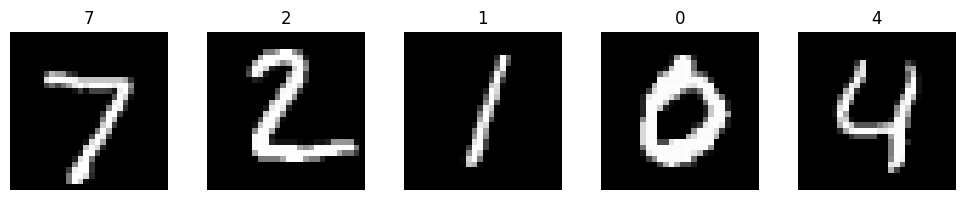

In [ ]:
# TODO: load MNIST via keras.datasets and assign to x_train, y_train, x_test, y_test
from tensorflow import keras
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# TODO: print shapes
print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape, y_test.shape)

# TODO: visualize first 5 samples using matplotlib (grayscale)
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(10,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(int(y_test[i]))
    plt.axis("off")
plt.tight_layout()

## A.3 Preprocess Data


In [ ]:
# TODO: normalize images to [0,1] and flatten to length 784
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
x_train = x_train.reshape((x_train.shape[0], 784))
x_test  = x_test.reshape((x_test.shape[0], 784))
num_classes = 10

# Sanity checks (do not modify)
assert x_train.shape[1] == 784 and x_test.shape[1] == 784, "Flattening incorrect"
print("Flattened:", x_train.shape, x_test.shape)

Flattened: (60000, 784) (10000, 784)


## A.4 Build a Shallow Network


In [ ]:
# TODO: build Sequential model: The Input will be 784.
# The first layer will be Dense of 128 neurons and use the ReLU activation function
# The second layer willbe Dense of 10 neurons and use the Softmax activation function
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## A.5 Compile and Train


In [ ]:
# TODO: compile with Adam(1e-3). The loss will be Sparse Categorical Cross Entropy
# Compile with the metric of Accuracy
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# TODO: train for 5 epochs with validation split of 10% and batch size of 128
history = model.fit(x_train, y_train, validation_split=0.1, epochs=5, batch_size=128, verbose=2)

Epoch 1/5
422/422 - 4s - 10ms/step - accuracy: 0.8941 - loss: 0.3838 - val_accuracy: 0.9560 - val_loss: 0.1684
Epoch 2/5
422/422 - 2s - 5ms/step - accuracy: 0.9498 - loss: 0.1731 - val_accuracy: 0.9665 - val_loss: 0.1207
Epoch 3/5
422/422 - 2s - 5ms/step - accuracy: 0.9642 - loss: 0.1246 - val_accuracy: 0.9700 - val_loss: 0.1034
Epoch 4/5
422/422 - 2s - 5ms/step - accuracy: 0.9719 - loss: 0.0971 - val_accuracy: 0.9733 - val_loss: 0.0958
Epoch 5/5
422/422 - 2s - 5ms/step - accuracy: 0.9774 - loss: 0.0796 - val_accuracy: 0.9747 - val_loss: 0.0879


## A.6 Evaluate, Predict, Visualize


Test accuracy: 0.9723 | Test loss: 0.0912


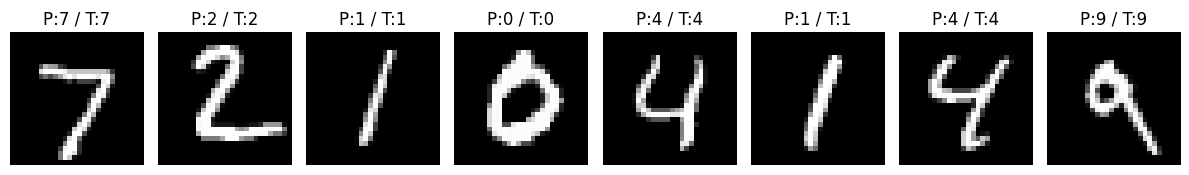

In [ ]:
# TODO: evaluate on test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

# TODO: predict and convert to labels with argmax
import numpy as np, matplotlib.pyplot as plt
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# TODO: show 8 images with predicted vs true labels
# Result should be Test accuracy: 0.9431 | Test loss: 0.1969 or something close
# and then pictures of numbers in the MNIST dataset
fig = plt.figure(figsize=(12,3))
for i in range(8):
    plt.subplot(1,8,i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray") # x_test
    plt.title(f"P:{int(y_pred[i])} / T:{int(y_test[i])}")  # y_test
    plt.axis("off")
plt.tight_layout()

## A.7 Answer the following discussion questions in Markdown. Please ensure your answers are robust, being composted of a minimum of 3 sentences each.

1. Why is it important to normalize image pixel values to the range [0, 1] before training a neural network, and what might happen to model performance if normalization is skipped?

Normalizing pixel values to the range [0,1] rather than [0,255] is necessary before training a neural network, as it improves the performance when training the data. Given that a pixel value is used as a input before being multiplied by a weight and passed through the neural network, having large values such as 230 or 240 could lead to problems with issues in training speed and accuracy. Furthermore, normalization enables the model to keep the scale of the weighted sums managable, as the computations that are being made are much more consistent with the range of 0-1 compared to that of 0-255.

## example: (normalized model)

w1 = 0.4, w2 = -0.3, w3 = 0.5

x1 = 1, x2 = 0.24, x3 = 0.8

(0.4 * 1) + (-0.3 * 0.24) + (0.5 * 0.8)

0.4 - 0.072 + 0.4 = 0.72

## example: (unnormalized model)

w1 = 0.9, w2 = 0.3, w3 = -0.5

x1 = 210, x2 = 140, x3 = 48

(0.9 * 210) + (0.3 * 140) + (-0.5 * 48)

189 + 42 - 24 = 207

The normalized model had a weighted sum of 0.72, and the unnormalized model has a weighted sum of 207. This example demonstrates how ensuring the data is normalized before training keeps the scale more consistent when weighted sums are being calculated within the neural network

2. In the Week 2 model, we used a single hidden layer with 128 units and a ReLU activation. How might increasing or decreasing the number of units in this layer affect training speed, overfitting risk, and model accuracy?

Increasing the number of neurons within the hidden layer would increase the amount of time it takes to train the model. For example if we used a hidden layer that consisted of 256 neurons, the neural network would need to double the number of computations for the weighted sum. In addition, having too many neurons in this layer would increase the risk of overfitting as the model may learn intricacies  in the training set that aren't necessarily indicative of what a number  is, and fail to do well on the test set. On the other hand, drastically reducing the number of neurons in the hidden layer may lead to lower rates of both training and test accuracy as the network could have a harder time understanding patterns.